In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score

feat = pd.read_csv("../data/processed/churn_features.csv")

X = feat[["Recency", "Frequency", "Monetary"]]
y = feat["Churn"]

# Pehle split, phir model (leakage se bachne ke liye)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

# Baseline 0: sab ko "churn" bol do
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Dummy accuracy:", round(dummy.score(X_test, y_test), 3))

# Baseline 1: Logistic Regression (log + scale pipeline ke andar)
logreg = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(random_state=42, max_iter=1000)),
])
logreg.fit(X_train, y_train)

pred = logreg.predict(X_test)
proba = logreg.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

(4196, 3) (1049, 3)
Dummy accuracy: 0.565
              precision    recall  f1-score   support

           0       0.73      0.64      0.68       456
           1       0.75      0.81      0.78       593

    accuracy                           0.74      1049
   macro avg       0.74      0.73      0.73      1049
weighted avg       0.74      0.74      0.74      1049

ROC-AUC: 0.791


In [36]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                    random_state=42, eval_metric="logloss")
xgb.fit(X_train, y_train)

pred_x = xgb.predict(X_test)
proba_x = xgb.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred_x))
print("ROC-AUC:", round(roc_auc_score(y_test, proba_x), 3))

              precision    recall  f1-score   support

           0       0.71      0.66      0.68       456
           1       0.75      0.79      0.77       593

    accuracy                           0.73      1049
   macro avg       0.73      0.73      0.73      1049
weighted avg       0.73      0.73      0.73      1049

ROC-AUC: 0.801


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, recall_score
from xgboost import XGBClassifier

feat2 = pd.read_csv("../data/processed/churn_features_v2.csv")
cols = ["Recency", "Frequency", "Monetary", "Tenure",
        "UniqueProducts", "Orders_Last90", "AvgOrderValue"]
X2 = feat2[cols]
y2 = feat2["Churn"]

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, stratify=y2, random_state=42
)

logreg2 = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(random_state=42, max_iter=1000)),
])
xgb2 = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                     random_state=42, eval_metric="logloss")

for name, model in [("LogReg (7 features)", logreg2), ("XGBoost (7 features)", xgb2)]:
    model.fit(X_train2, y_train2)
    pred = model.predict(X_test2)
    proba = model.predict_proba(X_test2)[:, 1]
    print(name,
          "| ROC-AUC:", round(roc_auc_score(y_test2, proba), 3),
          "| F1:", round(f1_score(y_test2, pred), 3),
          "| Recall:", round(recall_score(y_test2, pred), 3))

LogReg (7 features) | ROC-AUC: 0.795 | F1: 0.774 | Recall: 0.793
XGBoost (7 features) | ROC-AUC: 0.806 | F1: 0.78 | Recall: 0.804


In [38]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cols3 = ["Recency", "Frequency", "Monetary"]

tests = [
    ("LogReg, 3 features", logreg2, cols3),
    ("LogReg, 7 features", logreg2, cols),
    ("XGBoost, 3 features", xgb2, cols3),
    ("XGBoost, 7 features", xgb2, cols),
]
for name, model, c in tests:
    s = cross_val_score(model, X2[c], y2, cv=cv, scoring="roc_auc")
    print(name, "| mean AUC:", round(s.mean(), 3), "| std:", round(s.std(), 3))

LogReg, 3 features | mean AUC: 0.79 | std: 0.015
LogReg, 7 features | mean AUC: 0.795 | std: 0.011
XGBoost, 3 features | mean AUC: 0.796 | std: 0.01
XGBoost, 7 features | mean AUC: 0.803 | std: 0.007


In [39]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

spw = (y2 == 0).sum() / (y2 == 1).sum()
print("scale_pos_weight:", round(spw, 2))

xgb_w = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                      random_state=42, eval_metric="logloss",
                      scale_pos_weight=spw)

for name, model in [("XGBoost, normal", xgb2), ("XGBoost, class weight", xgb_w)]:
    r = cross_validate(model, X2[cols], y2, cv=cv,
                       scoring=["roc_auc", "f1", "recall"])
    print(name,
          "| AUC:", round(r["test_roc_auc"].mean(), 3),
          "| F1:", round(r["test_f1"].mean(), 3),
          "| Recall:", round(r["test_recall"].mean(), 3))

scale_pos_weight: 0.77
XGBoost, normal | AUC: 0.803 | F1: 0.774 | Recall: 0.811
XGBoost, class weight | AUC: 0.803 | F1: 0.755 | Recall: 0.746


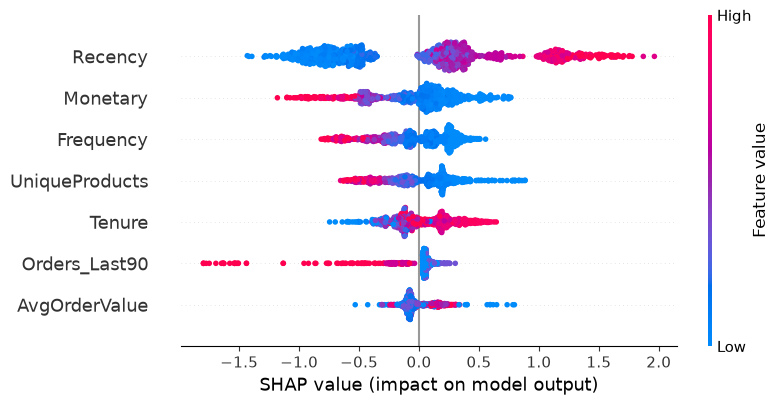

In [ ]:
import shap
import joblib
from xgboost import XGBClassifier

final_model = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                            random_state=42, eval_metric="logloss")
final_model.fit(X_train2, y_train2)

# Final model save karo (aage dashboard aur API me kaam aayega)
joblib.dump(final_model, "../models/churn_xgb.joblib")

explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_test2)

shap.plots.beeswarm(shap_values)       # sab customers ke liye overall tasveer

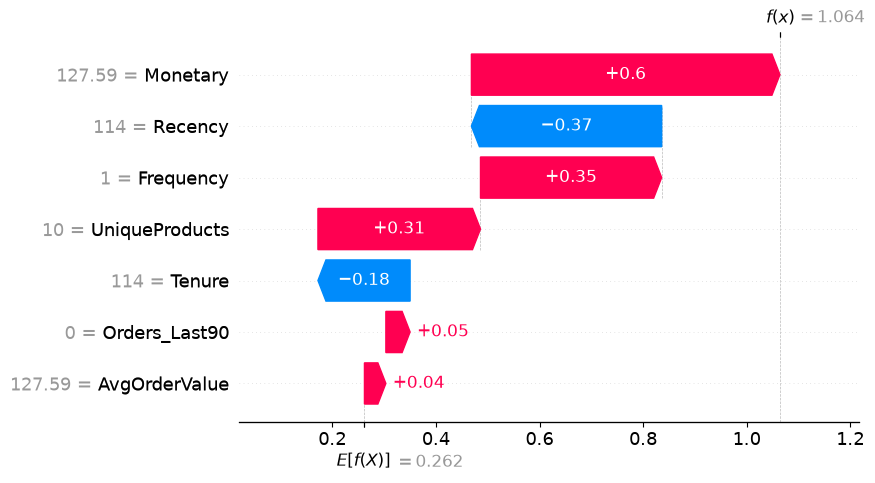

In [41]:
shap.plots.waterfall(shap_values[0])   # test set ke pehle customer ka risk kyun

In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs("../reports", exist_ok=True)

shap.plots.beeswarm(shap_values, show=False)
plt.savefig("../reports/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.close()

shap.plots.waterfall(shap_values[0], show=False)
plt.savefig("../reports/shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.close()